# Summative Lab: DataVine Analytics
Three projects: wine classification (k-NN), feed recommendations, and crime clustering.

## Project 1: Wine Classification (k-NN with PCA)
Goal: guess which of 3 wine types a wine is, using its chemical measurements.

In [38]:
import pandas as pd

wine = pd.read_csv("wine.csv")
chick = pd.read_csv("chickwts.csv")
arrests = pd.read_csv("USArrests.csv")

print(wine.head())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

In [39]:
print(wine.isnull().sum())
print(chick.isnull().sum())
print(arrests.isnull().sum())

alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64
weight    0
feed      0
dtype: int64
rownames    0
Murder      0
Assault     0
UrbanPop    0
Rape        0
dtype: int64


**Missing values:** Checked all three datasets (wine, chickwts, USArrests) for missing values. None were found, so no cleaning was needed.

In [40]:
#step 3- separate the answer from the measurements
from sklearn.preprocessing import StandardScaler

X = wine.drop("target", axis=1)
y = wine["target"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:3])

[[ 1.51861254 -0.5622498   0.23205254 -1.16959318  1.91390522  0.80899739
   1.03481896 -0.65956311  1.22488398  0.25171685  0.36217728  1.84791957
   1.01300893]
 [ 0.24628963 -0.49941338 -0.82799632 -2.49084714  0.01814502  0.56864766
   0.73362894 -0.82071924 -0.54472099 -0.29332133  0.40605066  1.1134493
   0.96524152]
 [ 0.19687903  0.02123125  1.10933436 -0.2687382   0.08835836  0.80899739
   1.21553297 -0.49840699  2.13596773  0.26901965  0.31830389  0.78858745
   1.39514818]]


**Standardizing:** The `target` column was separated from the measurements. The measurements were standardized so every column is on the same scale. The wine labels were already numeric (0, 1, 2), so no conversion was needed.

In [41]:
# step 4 -PCA
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)
X_pca = pca.fit_transform(X_scaled)

print("Columns before:", X_scaled.shape[1])
print("Columns after:", X_pca.shape[1])

Columns before: 13
Columns after: 10


PCA reduced the data from 13 columns to 10 while keeping 95% of the variance.

In [42]:
# Step 5: Split the data into a practice set and an exam set
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.2, random_state=42
)

print("Training wines:", X_train.shape[0])
print("Test wines:", X_test.shape[0])

Training wines: 142
Test wines: 36


**Train/test split:** The data was split into 142 training wines (80%) and 36 test wines (20%).

In [43]:
# Step 6: Meet k-NN, and let the computer find its best settings
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_neighbors": [1, 3, 5, 7, 9, 11],
    "metric": ["euclidean", "manhattan"]
}

grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5)
grid.fit(X_train, y_train)

print("Best settings:", grid.best_params_)
print("Best practice score:", grid.best_score_)

Best settings: {'metric': 'manhattan', 'n_neighbors': 3}
Best practice score: 0.9647783251231526


**Tuning:** GridSearchCV tested 12 combinations of k (1, 3, 5, 7, 9, 11) and distance metric (Euclidean, Manhattan). The best settings were the Manhattan metric with k = 3, scoring about 96% in cross-validation.

In [44]:
from sklearn.metrics import accuracy_score, classification_report

best_knn = grid.best_estimator_
y_pred = best_knn.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.9444444444444444
              precision    recall  f1-score   support

           0       0.93      1.00      0.97        14
           1       1.00      0.86      0.92        14
           2       0.89      1.00      0.94         8

    accuracy                           0.94        36
   macro avg       0.94      0.95      0.94        36
weighted avg       0.95      0.94      0.94        36



**Results:** The final model scored 94% accuracy on the 36 unseen test wines. It was strongest on types 0 and 2, and made 2 mistakes on type 1. Precision tells us how often a flagged type was correct, and recall tells us how many of each type the model managed to find.

## Project 2: Feed Recommendation (PCA and similarity)
Goal: recommend feeds that produce similar chicken weights.

In [45]:
# Step 1: Look at the data first
print(chick.head())
print(chick["feed"].value_counts())
print(chick.groupby("feed")["weight"].mean())

   weight       feed
0     179  horsebean
1     160  horsebean
2     136  horsebean
3     227  horsebean
4     217  horsebean
feed
soybean      14
linseed      12
sunflower    12
casein       12
meatmeal     11
horsebean    10
Name: count, dtype: int64
feed
casein       323.583333
horsebean    160.200000
linseed      218.750000
meatmeal     276.909091
soybean      246.428571
sunflower    328.916667
Name: weight, dtype: float64


In [46]:
# Step 2: Standardize the weight column
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
chick["weight_scaled"] = scaler.fit_transform(chick[["weight"]])

print(chick.head())

   weight       feed  weight_scaled
0     179  horsebean      -1.061762
1     160  horsebean      -1.306854
2     136  horsebean      -1.616444
3     227  horsebean      -0.442583
4     217  horsebean      -0.571578


In [47]:
# Step 3: One row per feed
feed_avg = chick.groupby("feed")["weight_scaled"].mean()
print(feed_avg)

feed
casein       0.803301
horsebean   -1.304274
linseed     -0.549004
meatmeal     0.201223
soybean     -0.191962
sunflower    0.872099
Name: weight_scaled, dtype: float64


In [48]:
# PCA down to one component
from sklearn.decomposition import PCA

pca_feed = PCA(n_components=1)
chick["pc1"] = pca_feed.fit_transform(chick[["weight_scaled"]])

print(chick.head())
print("Information kept:", pca_feed.explained_variance_ratio_)

   weight       feed  weight_scaled       pc1
0     179  horsebean      -1.061762 -1.061762
1     160  horsebean      -1.306854 -1.306854
2     136  horsebean      -1.616444 -1.616444
3     227  horsebean      -0.442583 -0.442583
4     217  horsebean      -0.571578 -0.571578
Information kept: [1.]


**Standardizing and PCA:** The weight column was standardized, then PCA reduced it to one principal component. Since there was only one feature, the component is identical to the standardized weight and keeps 100% of the variance.

In [49]:
# Step 5: Cosine similarity
from sklearn.metrics.pairwise import cosine_similarity
import pandas as pd

feed_pc1 = chick.groupby("feed")["pc1"].mean()
sim = cosine_similarity(feed_pc1.values.reshape(-1, 1))
sim_table = pd.DataFrame(sim, index=feed_pc1.index, columns=feed_pc1.index)

print(sim_table.round(2))

feed       casein  horsebean  linseed  meatmeal  soybean  sunflower
feed                                                               
casein        1.0       -1.0     -1.0       1.0     -1.0        1.0
horsebean    -1.0        1.0      1.0      -1.0      1.0       -1.0
linseed      -1.0        1.0      1.0      -1.0      1.0       -1.0
meatmeal      1.0       -1.0     -1.0       1.0     -1.0        1.0
soybean      -1.0        1.0      1.0      -1.0      1.0       -1.0
sunflower     1.0       -1.0     -1.0       1.0     -1.0        1.0


**Cosine similarity:** Cosine similarity was computed between feeds. Because each feed has only one value, the scores are only 1 or -1, so they show which feeds are on the same side of average but cannot rank how close they are.

In [50]:
# Step 6: Rank the feeds by how close they are
choice = "sunflower"
gaps = (feed_pc1 - feed_pc1[choice]).abs().sort_values()
print(gaps)

feed
sunflower    0.000000
casein       0.068798
meatmeal     0.670876
soybean      1.064061
linseed      1.421103
horsebean    2.176373
Name: pc1, dtype: float64


**Recommendations:** To rank similarity, the gap between each feed's PCA value and sunflower's was measured. Casein is the closest match (gap 0.07), followed by meatmeal (0.67). Horsebean is the least similar (2.18), which matches its much lower average chick weight.

## Project 3: Crime Pattern Analysis (K-Means and GMM)
Goal: group US states with similar crime profiles.

In [51]:
print(arrests.head())
print(arrests.describe())

     rownames  Murder  Assault  UrbanPop  Rape
0     Alabama    13.2      236        58  21.2
1      Alaska    10.0      263        48  44.5
2     Arizona     8.1      294        80  31.0
3    Arkansas     8.8      190        50  19.5
4  California     9.0      276        91  40.6
         Murder     Assault   UrbanPop       Rape
count  50.00000   50.000000  50.000000  50.000000
mean    7.78800  170.760000  65.540000  21.232000
std     4.35551   83.337661  14.474763   9.366385
min     0.80000   45.000000  32.000000   7.300000
25%     4.07500  109.000000  54.500000  15.075000
50%     7.25000  159.000000  66.000000  20.100000
75%    11.25000  249.000000  77.750000  26.175000
max    17.40000  337.000000  91.000000  46.000000


In [52]:
#step 2 Standardize
from sklearn.preprocessing import StandardScaler
import pandas as pd

states = arrests["rownames"]
crime = arrests.drop("rownames", axis=1)

scaler = StandardScaler()
crime_scaled = pd.DataFrame(
    scaler.fit_transform(crime),
    columns=crime.columns,
    index=states
)

print(crime_scaled.head())

              Murder   Assault  UrbanPop      Rape
rownames                                          
Alabama     1.255179  0.790787 -0.526195 -0.003451
Alaska      0.513019  1.118060 -1.224067  2.509424
Arizona     0.072361  1.493817  1.009122  1.053466
Arkansas    0.234708  0.233212 -1.084492 -0.186794
California  0.281093  1.275635  1.776781  2.088814


**Standardizing and feature selection:** The data was standardized so all columns are on the same scale. Murder, Assault and Rape were kept because they were strongly correlated with each other. UrbanPop had the weakest correlation (0.07 to 0.41), so it was dropped.

In [53]:
# step 3 Pick the top 3 features
print(crime_scaled.corr().round(2))

          Murder  Assault  UrbanPop  Rape
Murder      1.00     0.80      0.07  0.56
Assault     0.80     1.00      0.26  0.67
UrbanPop    0.07     0.26      1.00  0.41
Rape        0.56     0.67      0.41  1.00


In [54]:
#Step 4 keep these columns
features = crime_scaled[["Murder", "Assault", "Rape"]]
print(features.head())
print("Shape:", features.shape)

              Murder   Assault      Rape
rownames                                
Alabama     1.255179  0.790787 -0.003451
Alaska      0.513019  1.118060  2.509424
Arizona     0.072361  1.493817  1.053466
Arkansas    0.234708  0.233212 -0.186794
California  0.281093  1.275635  2.088814
Shape: (50, 3)


In [55]:
#step 5 PCA down to 2 components 
from sklearn.decomposition import PCA

pca_crime = PCA(n_components=2)
crime_pca = pca_crime.fit_transform(features)

print(crime_pca[:5])
print("Information kept:", pca_crime.explained_variance_ratio_)
print("Total kept:", pca_crime.explained_variance_ratio_.sum())

[[ 1.21019086 -0.84227709]
 [ 2.33218699  1.5394343 ]
 [ 1.51859328  0.50336289]
 [ 0.17777619 -0.32802946]
 [ 2.06600019  1.28549694]]
Information kept: [0.7861934  0.15268378]
Total kept: 0.9388771782627572


**PCA:** PCA reduced the 3 selected features to 2 principal components, which together keep about 94% of the variance.

In [56]:
import warnings
warnings.filterwarnings("ignore")

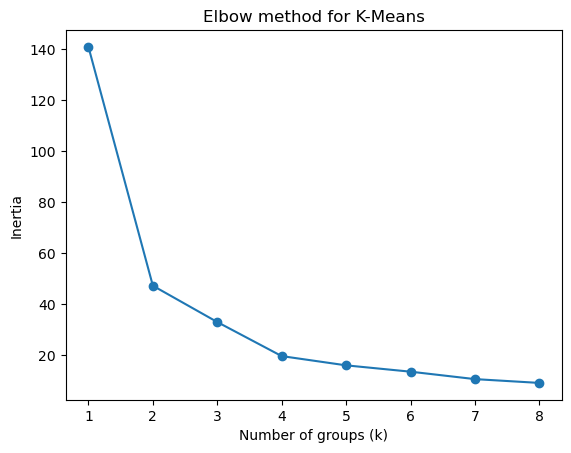

[140.8, 47.1, 32.9, 19.5, 15.9, 13.4, 10.5, 9.0]


In [57]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertias = []
k_values = range(1, 9)

for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    km.fit(crime_pca)
    inertias.append(km.inertia_)

plt.plot(k_values, inertias, marker="o")
plt.xlabel("Number of groups (k)")
plt.ylabel("Inertia")
plt.title("Elbow method for K-Means")
plt.show()

print([round(i, 1) for i in inertias])

**K-Means:** The elbow method showed inertia dropping sharply until k = 4 and then flattening, so 4 clusters were used. Group 0 is low crime, Group 3 is moderate, Group 1 has the highest murder rate, and Group 2 has the highest assault and rape rates.

In [58]:
from sklearn.cluster import KMeans
import pandas as pd

kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(crime_pca)

results = pd.DataFrame({
    "state": states.values,
    "kmeans_group": kmeans_labels
})

print(results["kmeans_group"].value_counts().sort_index())

for g in range(4):
    print(f"\nGroup {g}:")
    print(", ".join(results[results["kmeans_group"] == g]["state"]))

kmeans_group
0    14
1    12
2     7
3    17
Name: count, dtype: int64

Group 0:
Connecticut, Hawaii, Idaho, Iowa, Maine, Minnesota, Nebraska, New Hampshire, North Dakota, Rhode Island, South Dakota, Vermont, West Virginia, Wisconsin

Group 1:
Alabama, Florida, Georgia, Illinois, Louisiana, Maryland, Mississippi, New York, North Carolina, South Carolina, Tennessee, Texas

Group 2:
Alaska, Arizona, California, Colorado, Michigan, Nevada, New Mexico

Group 3:
Arkansas, Delaware, Indiana, Kansas, Kentucky, Massachusetts, Missouri, Montana, New Jersey, Ohio, Oklahoma, Oregon, Pennsylvania, Utah, Virginia, Washington, Wyoming


In [59]:
arrests["kmeans_group"] = kmeans_labels
print(arrests.groupby("kmeans_group")[["Murder", "Assault", "Rape"]].mean().round(1))

              Murder  Assault  Rape
kmeans_group                       
0                3.1     80.9  11.8
1               13.6    258.2  23.9
2               10.1    261.3  38.3
3                6.6    145.8  20.1


K-Means with k = 4 grouped the 50 states by crime profile. Group 0 is low crime, Group 3 is moderate, Group 1 has the highest murder rate, and Group 2 has the highest assault and rape rates

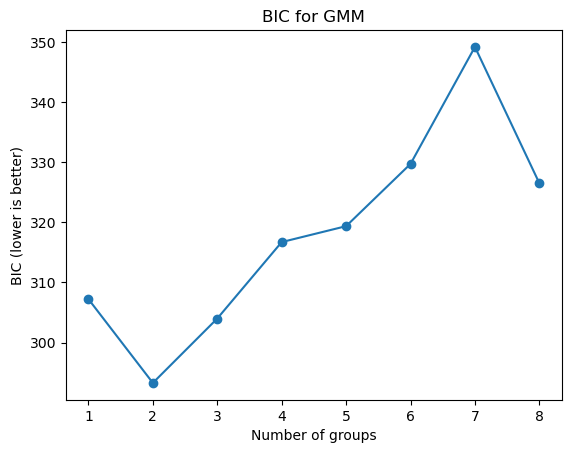

[np.float64(307.2), np.float64(293.3), np.float64(304.0), np.float64(316.7), np.float64(319.3), np.float64(329.7), np.float64(349.1), np.float64(326.5)]


In [60]:
# Step 8: GMM and BIC
import warnings
warnings.filterwarnings("ignore")

from sklearn.mixture import GaussianMixture
import matplotlib.pyplot as plt

bics = []
n_values = range(1, 9)

for n in n_values:
    gmm = GaussianMixture(n_components=n, random_state=42)
    gmm.fit(crime_pca)
    bics.append(gmm.bic(crime_pca))

plt.plot(n_values, bics, marker="o")
plt.xlabel("Number of groups")
plt.ylabel("BIC (lower is better)")
plt.title("BIC for GMM")
plt.show()

print([round(b, 1) for b in bics])

**GMM:** BIC was lowest at 2 components (293.3), so 2 were used. GMM split the states into a lower-crime group (31 states) and a higher-crime group (19 states), and also gives a confidence score for each state.

In [61]:
gmm = GaussianMixture(n_components=2, random_state=42)
gmm_labels = gmm.fit_predict(crime_pca)
gmm_probs = gmm.predict_proba(crime_pca)

arrests["gmm_group"] = gmm_labels
results["gmm_group"] = gmm_labels
results["confidence"] = gmm_probs.max(axis=1).round(2)

print(pd.Series(gmm_labels).value_counts().sort_index())
print(arrests.groupby("gmm_group")[["Murder", "Assault", "Rape"]].mean().round(1))
print(results.head())

0    31
1    19
Name: count, dtype: int64
           Murder  Assault  Rape
gmm_group                       
0             5.0    116.5  16.3
1            12.3    259.3  29.2
        state  kmeans_group  gmm_group  confidence
0     Alabama             1          1        1.00
1      Alaska             2          1        1.00
2     Arizona             2          1        0.97
3    Arkansas             3          0        0.99
4  California             2          1        1.00


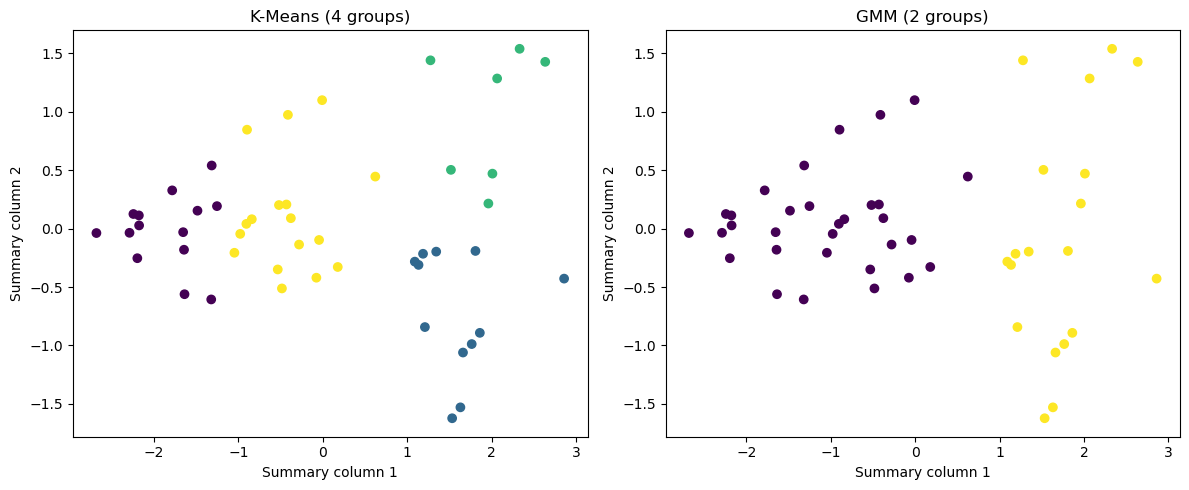

In [62]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(crime_pca[:, 0], crime_pca[:, 1], c=kmeans_labels, cmap="viridis")
axes[0].set_title("K-Means (4 groups)")
axes[0].set_xlabel("Summary column 1")
axes[0].set_ylabel("Summary column 2")

axes[1].scatter(crime_pca[:, 0], crime_pca[:, 1], c=gmm_labels, cmap="viridis")
axes[1].set_title("GMM (2 groups)")
axes[1].set_xlabel("Summary column 1")
axes[1].set_ylabel("Summary column 2")

plt.tight_layout()
plt.show()

**Comparison:** Both methods find the same basic split between lower-crime and higher-crime states. K-Means divides each side further into 4 groups, separating the two high-crime groups by crime type (murder versus assault and rape). GMM chose 2 groups, which is a broader split, and it also gives probabilities, so it shows how sure it is about each state.

In [ ]:
# summarizing the datasets
for name, file in [("Wine", "wine.csv"), ("Chickwts", "chickwts.csv"), ("USArrests", "USArrests.csv")]:
    df = pd.read_csv(file)
    print(name, "- rows and columns:", df.shape)
    print(df.dtypes)
    print()

Wine - rows and columns: (178, 14)
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

Chickwts - rows and columns: (71, 2)
weight     int64
feed      object
dtype: object

USArrests - rows and columns: (50, 5)
rownames     object
Murder      float64
Assault       int64
UrbanPop      int64
Rape        float64
dtype: object

